Name: Divyadharshini S
Roll no: 24BAD022
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Dataset Information
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Number of training samples: 60000
Number of testing samples: 10000


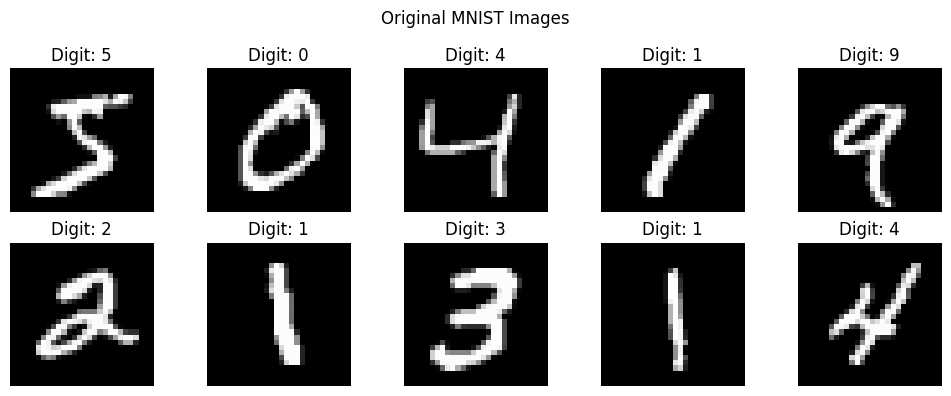


Prepared Dataset
Training shape: (54000, 784)
Validation shape: (6000, 784)
Testing shape: (10000, 784)


In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("\nDataset Information")
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Number of training samples:", len(x_train))
print("Number of testing samples:", len(x_test))

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

x_train, x_val = train_test_split(
    x_train,
    test_size=0.1,
    random_state=42
)

print("\nPrepared Dataset")
print("Training shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Testing shape:", x_test.shape)


In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

input_dim = 784
encoding_dim = 32
input_layer = Input(shape=(input_dim,))
encoder_layer = Dense(128, activation="relu")(input_layer)
encoder_layer = Dense(64, activation="relu")(encoder_layer)
bottleneck = Dense(
    encoding_dim,
    activation="relu",
    name="bottleneck"
)(encoder_layer)

decoder_layer = Dense(64, activation="relu")(bottleneck)
decoder_layer = Dense(128, activation="relu")(decoder_layer)

output_layer = Dense(
    input_dim,
    activation="sigmoid"
)(decoder_layer)

autoencoder = Model(input_layer, output_layer)
encoder = Model(input_layer, bottleneck)

latent_input = Input(shape=(encoding_dim,))
decoder_output = autoencoder.layers[-3](latent_input)
decoder_output = autoencoder.layers[-2](decoder_output)
decoder_output = autoencoder.layers[-1](decoder_output)

decoder = Model(latent_input, decoder_output)
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)
print("AUTOENCODER MODEL SUMMARY")
autoencoder.summary()
print("\nENCODER MODEL SUMMARY")
encoder.summary()
print("\nDECODER MODEL SUMMARY")
decoder.summary()


Name: Divyadharshini S
Roll no: 24BAD022
AUTOENCODER MODEL SUMMARY


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

Name: Divyadharshini S
Roll no: 24BAD022
Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0690 - val_loss: 0.0419
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0332 - val_loss: 0.0278
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0250 - val_loss: 0.0229
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0214 - val_loss: 0.0200
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0191 - val_loss: 0.0182
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0175 - val_loss: 0.0170
Epoch 7/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 0.0163 - val_loss: 0.0160
Epoch 8/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0154 - val_loss: 0.0150
Epoch 9/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 0.0146 - val_loss: 0.0144
Epoch 10/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0140 - val_loss: 0.0139
Epoch 11/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0136 - val_loss: 0.0134

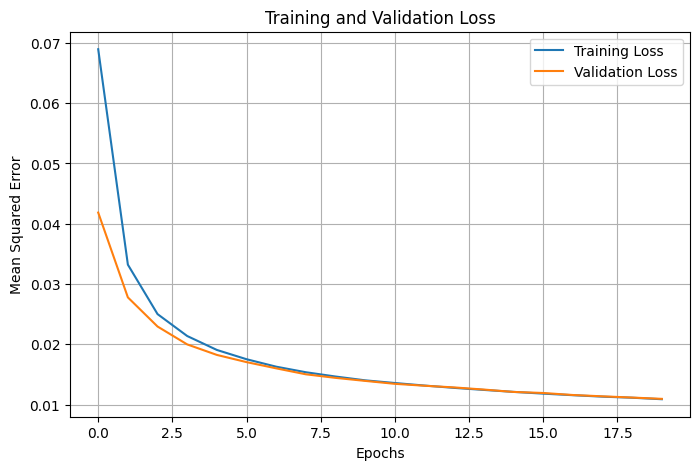

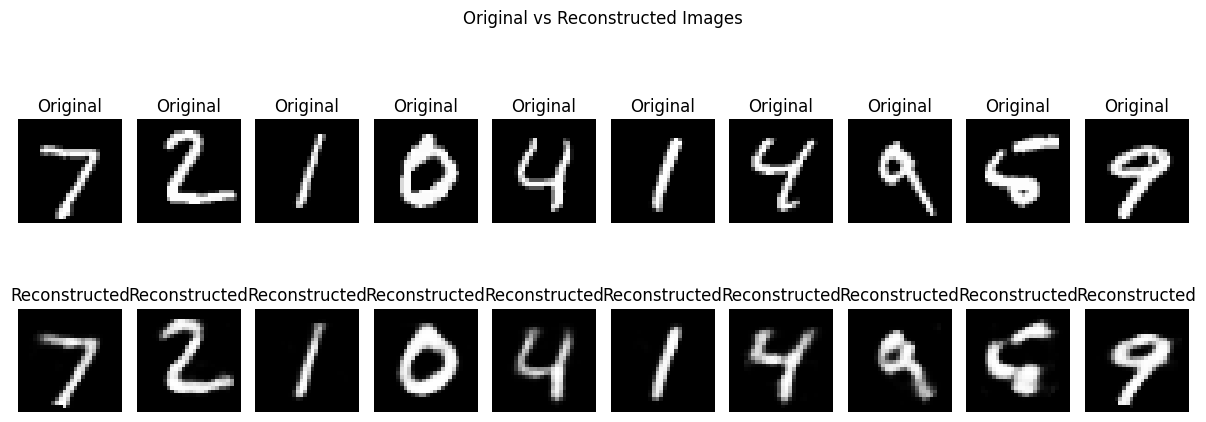

In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_val, x_val),
    verbose=1
)
test_loss = autoencoder.evaluate(
    x_test,
    x_test,
    verbose=0
)
print("\nModel Evaluation")
print("Test Reconstruction MSE:", test_loss)

reconstructed_images = autoencoder.predict(x_test)
mse = np.mean((x_test - reconstructed_images) ** 2)
print("Reconstruction Mean Squared Error:", mse)

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed Images")
plt.tight_layout()
plt.show()


Name: Divyadharshini S
Roll no: 24BAD022
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Original Data Dimensions: (10000, 784)
Compressed Data Dimensions: (10000, 32)

Dimensionality Reduction
Original Features: 784
Latent Features: 32
Compression Ratio: 24.5 :1


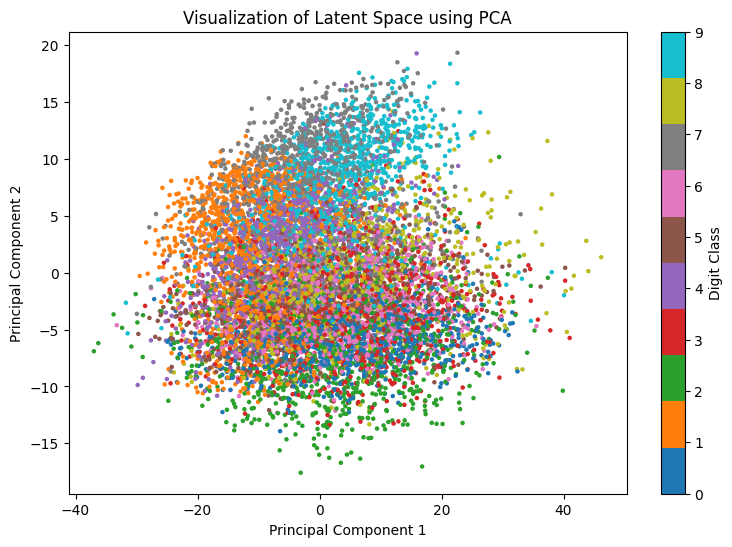

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step


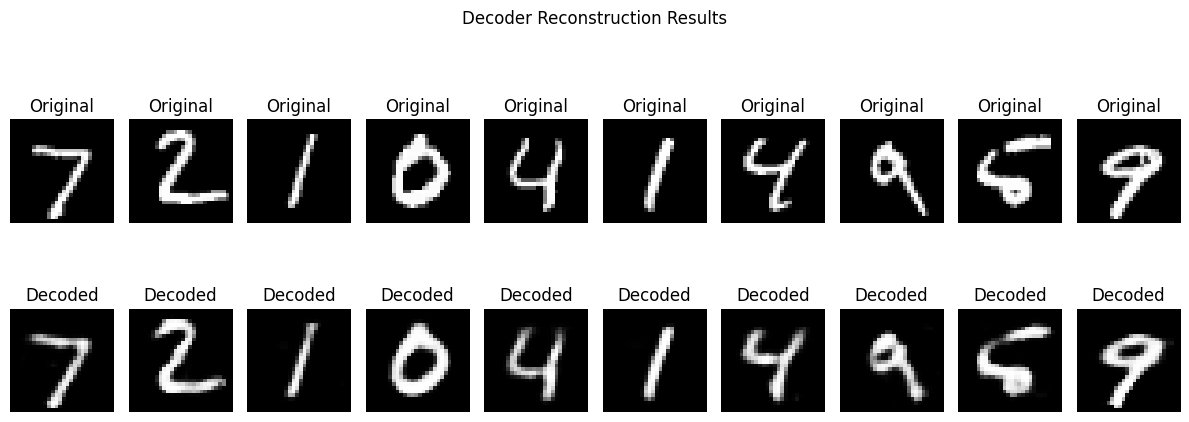


PCA Explained Variance: 0.4166793


In [6]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
from sklearn.decomposition import PCA

latent_features = encoder.predict(x_test)
print("Original Data Dimensions:", x_test.shape)
print("Compressed Data Dimensions:", latent_features.shape)
print("\nDimensionality Reduction")
print("Original Features:", x_test.shape[1])
print("Latent Features:", latent_features.shape[1])

compression_ratio = (
    x_test.shape[1] / latent_features.shape[1]
)

print("Compression Ratio:", compression_ratio, ":1")
pca = PCA(n_components=2)

latent_2d = pca.fit_transform(latent_features)
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test,
    cmap="tab10",
    s=5
)

plt.colorbar(scatter, label="Digit Class")
plt.title("Visualization of Latent Space using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

selected_features = latent_features[:10]
decoded_images = decoder.predict(selected_features)
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap="gray")
    plt.title("Decoded")
    plt.axis("off")

plt.suptitle("Decoder Reconstruction Results")
plt.tight_layout()
plt.show()

print(
    "\nPCA Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

autoencoder.save("mnist_autoencoder.keras")
encoder.save("mnist_encoder.keras")
decoder.save("mnist_decoder.keras")
